# Message 与提示词模板


## 为什么第二次提问时，模型不知道我是谁？

第一次说“我叫张三”，第二次问“我叫什么”，模型是否能答出来，取决于第二次请求有没有包含前一次的信息。普通聊天 API 调用通常不会替应用保存会话历史；只传新问题，模型就只能根据本次输入回答。

这一章解决两个问题：**用 Message 表达一次对话中的角色和内容，用提示词模板生成可复用的消息结构。** 对话历史由应用维护，再作为上下文传给模型。

本篇根据尚硅谷第 04 章的 42 页课件整理。代码全部放在 Markdown 代码块中，仅供阅读，不作为 Notebook 的可执行单元格。

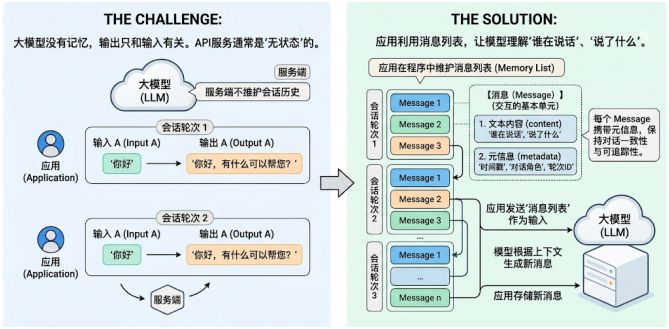

课件图示：应用维护消息列表，在后续请求中传入需要的历史。


## Message：先分清谁说了什么

Message 是 LangChain 与聊天模型交互的基本单元。可以从三个角度理解：

| 部分 | 回答的问题 | 例子 |
| --- | --- | --- |
| 角色 / 类型 | 谁在说话？ | system、user、assistant、tool |
| `content` | 说了什么？ | 文本，或包含图片等内容的块列表 |
| 附加字段 | 这条消息怎样识别、关联或追踪？ | `id`、`name`、`tool_call_id`、响应元数据 |

“元信息”是概念上的分类，不表示所有信息都写进一个名叫 `metadata` 的参数。消息类有各自的字段；`response_metadata`、`usage_metadata` 的用途也不同。

LangChain 提供统一消息对象，由模型集成包转换成供应商要求的格式。统一接口能减少适配代码，但供应商是否支持某种角色、附加字段或输入模态，仍要看具体模型与集成。


## 四种常见角色：system、user、assistant、tool

| 字典中的角色 | LangChain 对象 | 用途 |
| --- | --- | --- |
| `system` | `SystemMessage` | 设定角色、任务规则和回答风格 |
| `user` | `HumanMessage` | 用户提出的问题或提供的资料 |
| `assistant` | `AIMessage` | 模型回复，也可能包含工具调用请求 |
| `tool` | `ToolMessage` | 应用执行工具后，将结果交回模型 |

在聊天模板中，`human` 是 `user` 的常见别名，`ai` 是 `assistant` 的常见别名。消息对象的 `.type` 常见值是 `human`、`ai` 等，不必与供应商 API 的角色字符串完全相同。

系统消息像工作说明，用户消息是本次任务。把“System: …”写进普通用户字符串，不等于真正创建了一条系统消息。


## 消息的两种写法：字典与对象

同一段对话可以用字典列表表达：

~~~python
dict_messages = [
    {"role": "system", "content": "你是耐心的 Python 导师。"},
    {"role": "user", "content": "我叫张三。"},
    {"role": "assistant", "content": "张三，你好！"},
    {"role": "user", "content": "我叫什么？"},
]
~~~

也可以用消息对象表达：

~~~python
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage

object_messages = [
    SystemMessage(content="你是耐心的 Python 导师。"),
    HumanMessage(content="我叫张三。"),
    AIMessage(content="张三，你好！"),
    HumanMessage(content="我叫什么？"),
]
~~~

课件把第一种称为“JSON 格式”，这里实际写的是 **Python 字典**。JSON 文本是序列化后的字符串；将整段字典列表转换成 JSON 字符串再传给模型，会失去原本的消息输入结构。

简单输入用字典很直观；需要读写工具调用、用量和多模态字段时，消息对象更方便。


## 本章模型调用的公共配置

只构造消息、格式化模板，不需要模型密钥。后文出现 `model.invoke()` 或 `model.stream()` 时，假定已按本节创建 `model`；从第 02 章沿用已配置的模型也可以。

课件使用 OpenAI 兼容服务及 `CLOSEAI_*` 环境变量。按该方式学习，需要以下依赖：

~~~bash
uv add langchain langchain-openai python-dotenv
~~~

`.env` 示例：

~~~dotenv
CLOSEAI_API_KEY=你的模型服务密钥
CLOSEAI_BASE_URL=服务商提供的OpenAI兼容API地址
CHAT_MODEL=账户可用的模型名称
~~~

~~~python
import os
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model

load_dotenv()

model = init_chat_model(
    model=os.environ["CHAT_MODEL"],
    model_provider="openai",
    api_key=os.environ["CLOSEAI_API_KEY"],
    base_url=os.environ["CLOSEAI_BASE_URL"],
)
~~~

这些是兼容服务的项目变量名；直连其他供应商时，要使用对应集成包和配置。课件通过兼容网关调用其他厂商模型，也不能据此把该厂商的原生 `model_provider` 都写成 `openai`。


## 调用模型：输入消息列表，得到 AIMessage

下面接着使用前两节的 `model` 与 `object_messages`：

~~~python
response = model.invoke(object_messages)

print(response.content)
print(response.usage_metadata)
print(response.response_metadata)
~~~

`invoke()` 在这里返回一条 `AIMessage`，并非自动更新后的完整会话列表。字典列表也可以作为输入：

~~~python
response = model.invoke(dict_messages)
~~~

普通文本回答通常能直接查看 `.content`。需要处理文本、推理块、图片或工具调用时，继续看消息的结构化字段，不能把所有响应都假定为纯字符串。


## SystemMessage 与 HumanMessage 的常用字段

`SystemMessage("你是助手")` 与 `SystemMessage(content="你是助手")` 是两种等价写法；`HumanMessage` 也支持把内容作为第一个位置参数。笔记中多写 `content=`，方便看清字段。

~~~python
from langchain_core.messages import HumanMessage

message = HumanMessage(
    content="请用一句话解释消息列表。",
    name="alice",
    id="msg_001",
)

print(message.content)
print(message.name)
print(message.id)
~~~

| 字段 | 含义 | 容易误解的地方 |
| --- | --- | --- |
| `content` | 消息正文 | 可以是字符串，也可以是内容块列表 |
| `name` | 消息发送者的可选名称 | 是否转发给模型、模型如何利用它，取决于集成和供应商 |
| `id` | 消息标识 | 不等于会话 ID，不会让模型自动记住这条消息 |

课件用 Bob、Tom 的多名说话者示例演示 `name`，并观察到某个版本的网关 / 集成没有传递预期信息。这是课件环境的现象，不能推广为所有版本都不支持。业务必须识别人名时，也应在正文里明确表达。


## AIMessage：正文、响应元数据与 Token 用量

模型输出除了回答，还可能包含运行信息：

| 字段 | 重点看什么 |
| --- | --- |
| `content` | 回答正文或供应商返回的内容块 |
| `response_metadata` | 模型名、结束原因、供应商原始用量等响应信息 |
| `usage_metadata` | LangChain 统一表示的输入、输出、总 Token 数等 |
| `tool_calls` | 模型请求调用的工具列表 |
| `invalid_tool_calls` | 未能正确解析的工具调用信息 |
| `additional_kwargs` | 集成保留的额外字段，结构与供应商有关 |

读取用量时，要考虑响应可能没有提供它：

~~~python
usage = response.usage_metadata or {}
print("输入 Token：", usage.get("input_tokens"))
print("输出 Token：", usage.get("output_tokens"))
print("总 Token：", usage.get("total_tokens"))
print("结束原因：", response.response_metadata.get("finish_reason"))
~~~

`response_metadata` 在基础消息类中也有，并非只有 AIMessage 才能拥有。`usage_metadata` 方便统一读取用量，但详细缓存、音频、推理 Token 字段以及是否返回这些信息，仍与模型和调用方式有关。不要依赖课件中某一次调用的完整日志结构。


## ToolMessage：把工具结果与调用请求配对

模型“请求使用工具”和应用“真正执行工具”是两个步骤。`AIMessage.tool_calls` 描述前者，`ToolMessage.content` 保存后者的结果。

~~~text
HumanMessage：北京天气如何？
    ↓
AIMessage.tool_calls：get_weather(city="北京"), id="call_weather_001"
    ↓ 应用执行工具
ToolMessage：北京：晴天；tool_call_id="call_weather_001"
    ↓ 模型基于结果继续回答
AIMessage：北京今天晴天。
~~~

手工构造一个有效的教学消息序列：

~~~python
from langchain_core.messages import HumanMessage, AIMessage, ToolMessage

messages = [
    HumanMessage(content="北京天气如何？"),
    AIMessage(
        content="",
        tool_calls=[{
            "name": "get_weather",
            "args": {"city": "北京"},
            "id": "call_weather_001",
            "type": "tool_call",
        }],
    ),
    ToolMessage(
        content="北京：晴天。",
        name="get_weather",
        tool_call_id="call_weather_001",
    ),
]

final_response = model.invoke(messages)
~~~

`tool_call_id` 必须对应前面 AI 消息中的调用 ID。普通的“让我查一下”正文不能替代 `tool_calls`。一次 AI 消息有多个工具请求时，需要为每个请求返回匹配的结果；结果可组成连续的工具消息段，并非每条 ToolMessage 都必须单独紧挨同一条 AIMessage。


### bind_tools 不会替应用执行工具

下面预览一次完整流程。天气函数返回的是固定的教学数据，不是真实查询：

~~~python
from langchain_core.messages import HumanMessage, ToolMessage
from langchain_core.tools import tool

@tool
def get_weather(city: str) -> str:
    """返回城市天气的教学示例。"""
    return f"{city}：晴天（模拟数据）。"

tools_by_name = {get_weather.name: get_weather}
model_with_tools = model.bind_tools([get_weather])
messages = [HumanMessage(content="北京天气如何？")]

ai_message = model_with_tools.invoke(messages)
messages.append(ai_message)

if ai_message.tool_calls:
    for call in ai_message.tool_calls:
        result = tools_by_name[call["name"]].invoke(call["args"])
        messages.append(ToolMessage(
            content=str(result),
            name=call["name"],
            tool_call_id=call["id"],
        ))
    final_response = model_with_tools.invoke(messages)
else:
    final_response = ai_message

print(final_response.content)
~~~

`bind_tools()` 把工具描述交给模型，模型未必一定调用工具。这个例子处理一次工具调用阶段；实际 Agent 若连续请求工具，需要循环执行，并处理错误和停止条件，后续 Tools 章节再展开。

工具参数名也要一致：函数声明 `city`，调用参数就用 `city`，不要把课件中的 `location` 混进来。


## 多轮对话：保存用户消息，也保存 AI 回复

模型不知道上一次的回答，后续的“再解释一下”“把刚才的结果乘以 4”就可能失去指代对象。因此，每轮需要保存用户输入和模型返回。

~~~python
from langchain_core.messages import SystemMessage, HumanMessage

history = [SystemMessage(content="你是一个友好的助手。")]

history.append(HumanMessage(content="我叫张三。"))
reply1 = model.invoke(history)
history.append(reply1)

history.append(HumanMessage(content="我叫什么？"))
reply2 = model.invoke(history)
history.append(reply2)
~~~

直接保存 `AIMessage` 对象，可以保留正文之外的工具调用等信息。若只保存 `reply.content` 并重新创建字典，可能丢掉后续需要的字段。

这里需要保留的是**上下文信息**，不是强制使用同一个 Python 列表对象。只要新列表仍包含所需历史，就可以重新构造；仅用新问题覆盖历史，才会丢失上下文。


## 历史会越来越长：保留最近 N 轮

全量历史最直观，但对话越长，输入 Token、延迟和费用越高，还会超过模型上下文窗口。课件先采用“保留系统消息与最近 N 轮”的办法。

下面限定为：第一条是系统消息，后续是完整的 `HumanMessage → AIMessage` 纯聊天轮次；**在添加当前新问题之前裁剪**。

~~~python
from langchain_core.messages import SystemMessage

def keep_recent_pairs(messages, max_pairs=3):
    """裁剪已完成的纯聊天历史，不适用于工具或复杂消息序列。"""
    if max_pairs < 0:
        raise ValueError("max_pairs 不能为负数")
    has_system = bool(messages) and isinstance(messages[0], SystemMessage)
    system = messages[:1] if has_system else []
    conversation = messages[1:] if has_system else messages
    recent = conversation[-2 * max_pairs:] if max_pairs else []
    return system + recent
~~~

例如已有 system 加 3 轮问答，共 7 条消息；保留最近 2 轮后为 5 条，再加入新用户问题，实际发送 6 条。

### 为什么不能在加入问题后直接取最后 2N 条？

新问题没有对应 AI 回复，消息数变成奇数，机械切片可能从上一轮 AI 回复开始，留下半轮对话。工具调用也不是固定两条消息，不能使用同一规则。

轮数限制只是粗略控制；长文消息仍可能超出 Token 预算。实际应用可使用 `trim_messages` 等工具按 Token 裁剪，或采用摘要与检索，同时保留工具调用和工具结果的完整配对。更早的消息被删除后，模型无法可靠回答“我最开始问了什么”。


## 课件实战：流式多轮聊天机器人

这个例子接着使用公共配置的 `model` 和上一节的 `keep_recent_pairs()`，仅演示普通文本聊天。流程是“裁剪已完成历史 → 加入新问题 → 流式输出 → 保存完整 AI 消息”。

~~~python
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_core.messages import message_chunk_to_message

history = [SystemMessage(content="你是小谷，一名耐心、友好的助手。")]
max_pairs = 3

while True:
    question = input("你：").strip()
    if question.lower() == "quit":
        break
    if not question:
        continue

    history = keep_recent_pairs(history, max_pairs=max_pairs)
    request_messages = history + [HumanMessage(content=question)]
    full_chunk = None

    print("小谷：", end="", flush=True)
    for chunk in model.stream(request_messages):
        full_chunk = chunk if full_chunk is None else full_chunk + chunk
        for block in chunk.content_blocks:
            if block.get("type") == "text":
                print(block.get("text", ""), end="", flush=True)
    print()

    if full_chunk is not None:
        history = request_messages + [message_chunk_to_message(full_chunk)]
~~~

流式响应通常是一串 `AIMessageChunk`，把 chunk 相加，再转成 `AIMessage` 保存，比只拼字符串能保留更多结构。输出时只显示文本块，避免把内容块列表当字符串相加。

这段代码没有加入工具执行循环；若模型返回工具请求，需要用上一节的工具流程处理。网络失败时也要决定是否重试，不能把没有完成的回复保存成正常轮次。


## content：一条消息可以同时包含文字和图片

纯文本通常写成字符串；多模态消息常写成内容块列表。下面是 OpenAI 兼容的图片输入格式，模型本身需要支持图像输入。

~~~python
import base64
from pathlib import Path
from langchain_core.messages import HumanMessage

image_path = Path("image_test.png")
encoded = base64.b64encode(image_path.read_bytes()).decode("ascii")
data_uri = f"data:image/png;base64,{encoded}"

message = HumanMessage(content=[
    {"type": "text", "text": "这张图里有什么？"},
    {"type": "image_url", "image_url": {"url": data_uri}},
])

response = model.invoke([message])
print(response.content)
~~~

`image_url.url` 也可以是模型服务能够访问的图片 URL。本地磁盘路径不能直接充当远程服务可读取的 URL，需要读取文件并编码，或提供可访问的地址。

本例读取 PNG，Data URI 就写 `image/png`；JPEG 则用 `image/jpeg`。课件图片是 PNG，不能沿用与文件不符的 JPEG 默认类型。

下图是课件识图示例中的图片。示例代码的 `image_test.png` 需要另行放到脚本工作目录，Notebook 的内嵌附件不会自动变成该磁盘文件。

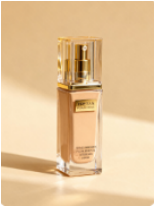

课程示例图片：香水瓶；可用自己的本地 PNG 替换。


## content_blocks：用统一结构表达多模态内容

不同厂商对图片、音频、推理内容的字段定义不同。LangChain 1.x 的 `content_blocks` 提供标准内容块结构，每个块通过 `type` 区分用途。

| 常见类型 | 含义 | 典型字段 |
| --- | --- | --- |
| `text` | 文本 | `text` |
| `image` | 图片 | `url`，或 `base64` 与 `mime_type` |
| `audio` / `video` | 音频 / 视频 | 数据来源、MIME 类型等，按该块规范填写 |
| `reasoning` | 供应商公开返回的推理相关内容 | `reasoning` 或相应的结构化信息 |
| `tool_call` | 工具调用内容块 | 名称、参数、ID 等 |

把上一节图片改成标准内容块：

~~~python
import base64
from pathlib import Path
from langchain_core.messages import HumanMessage

encoded = base64.b64encode(Path("image_test.png").read_bytes()).decode("ascii")

message = HumanMessage(content_blocks=[
    {"type": "text", "text": "这张图里有什么？"},
    {"type": "image", "base64": encoded, "mime_type": "image/png"},
])

response = model.invoke([message])
~~~

这里的 `base64` 是编码数据本身，不加 `data:image/...` 前缀。标准块仍要由集成转换，不能让不支持视觉的模型获得视觉能力；切换模型时也要核对模态、字段及集成版本。


### 输出时：正文与推理相关内容分开读取

`content` 保留原始内容表示；访问 `content_blocks` 时，LangChain 按消息及集成信息解析标准内容块，不必对所有供应商手写不同的字段读取逻辑。

~~~python
for block in response.content_blocks:
    block_type = block.get("type")
    if block_type == "text":
        print("回答：", block.get("text", ""))
    elif block_type == "reasoning":
        print("推理相关内容：", block.get("reasoning", ""))
~~~

课件用 DeepSeek 返回的 `additional_kwargs["reasoning_content"]` 演示转换。是否能得到对应标准块，取决于供应商实际返回的信息与集成的解析支持；不是每个模型都会返回推理文字，也不能把这些块视为模型全部内部思考的完整记录。

展示回答时筛选 `text`，需要研究输出结构时再检查其他块。工具调用还可以通过 `AIMessage.tool_calls` 读取，不必依赖正文里是否出现了工具名称。


## 为什么还需要提示词模板？

消息解决“谁说了什么”，模板解决“相同结构怎样填入不同数据”。只有一个临时问题时，f-string 很方便；角色、风格、历史和任务都需要复用时，模板更容易维护。

~~~python
topic = "Python 列表"
level = "初学者"
text = f"你是编程导师，请为{level}解释{topic}。"
~~~

提示词模板把固定说明和变化数据分开：

| 需要处理的事 | 直接拼字符串 | 提示词模板 |
| --- | --- | --- |
| 填入变量 | f-string、字符串 format | 声明占位符，传变量字典 |
| 多角色结构 | 自行管理每条消息 | 用 ChatPromptTemplate 集中定义 |
| 历史插入 | 自行拼接消息列表 | 使用 MessagesPlaceholder |
| 固定部分复用 | 自行抽函数或常量 | partial、嵌套和组合 |
| 接入流程 | 手工传给下个组件 | 支持 Runnable 接口及 `|` 组合 |

模板能检查必需变量是否缺失，但不会自动证明内容正确，也不保证模型严格遵守全部规则。不要把“变量校验”理解为完整业务校验。


## PromptTemplate：生成一段文本

`PromptTemplate` 适合需要生成单段文本的场景，角色边界不由它单独维护。

~~~python
from langchain_core.prompts import PromptTemplate

template = PromptTemplate.from_template(
    "你是编程导师，请为{level}解释{topic}。"
)

print(template.input_variables)
text = template.format(level="初学者", topic="Python 列表")
value = template.invoke({"level": "初学者", "topic": "Python 列表"})

print(text)
print(value.to_string())
~~~

| 调用 | 返回 |
| --- | --- |
| `template.format(...)` | `str` |
| `template.invoke({...})` | `StringPromptValue` |

聊天模型也可以接受字符串或 PromptValue 输入，由 LangChain 转换；不能把课件的演进描述理解为“现代 ChatModel 完全不能接收字符串”。需要系统消息与历史角色时，用 ChatPromptTemplate 更直接。


## ChatPromptTemplate：生成有角色的聊天提示

`ChatPromptTemplate` 描述一组消息的模板结构。常用方式是 `from_messages()`，列表中的元组依次写角色和内容模板。

~~~python
from langchain_core.prompts import ChatPromptTemplate

chat_template = ChatPromptTemplate.from_messages([
    ("system", "你是耐心的编程导师，你的名字是{name}。"),
    ("human", "你好！"),
    ("ai", "你好，请告诉我你想学习什么。"),
    ("human", "请为{level}解释{topic}。"),
])

prompt_value = chat_template.invoke({
    "name": "小谷",
    "level": "初学者",
    "topic": "Python 列表",
})
print(prompt_value.to_messages())
~~~

也可以直接构造：

~~~python
chat_template = ChatPromptTemplate([
    ("system", "你是{name}，一名编程导师。"),
    ("human", "{question}"),
])
~~~

前例的固定 Human / AI 消息可以作为演示上下文，适合示例引导；它们不会自动变成真实历史。真实对话历史应从应用的会话状态中传入。


## invoke、format、format_messages：返回值不同

同一个聊天模板可以用三种方法格式化：

| 方法 | 参数形式 | 返回值 | 常见用途 |
| --- | --- | --- | --- |
| `invoke()` | 变量字典 | `ChatPromptValue` | 接入 Runnable 流程，或直接传给模型 |
| `format()` | 关键字参数 | `str` | 阅读和打印模板结果 |
| `format_messages()` | 关键字参数 | `list[BaseMessage]` | 直接拿消息列表交给模型 |

~~~python
from langchain_core.prompts import ChatPromptTemplate

prompt = ChatPromptTemplate.from_messages([
    ("system", "你是{name}。"),
    ("human", "{question}"),
])
variables = {"name": "小谷", "question": "你能帮我做什么？"}

value = prompt.invoke(variables)
text = prompt.format(**variables)
messages = prompt.format_messages(**variables)

print(type(value).__name__)       # ChatPromptValue
print(type(text).__name__)        # str
print(type(messages).__name__)    # list
print(value.to_messages())
print(value.to_string())
~~~

`format()` 得到的字符串一般含 `System:`、`Human:` 等可读前缀。再把这个字符串当普通输入传给模型时，不能依靠这些前缀保持原始角色边界。调用聊天模型优先传 PromptValue 或消息列表。

**模板的 `invoke()` 只格式化提示词，不会调用模型；模型的 `invoke()` 才产生模型响应。**


## 模板接模型：先格式化，再调用

课件的年龄问题可以整理成两步：

~~~python
from langchain_core.prompts import ChatPromptTemplate

math_prompt = ChatPromptTemplate.from_messages([
    ("system", "请仔细分析数学问题，给出简短计算过程。"),
    ("human", "{question}"),
])
variables = {
    "question": "我今年18岁，舅舅38岁，爷爷72岁。我和舅舅一共多少岁？"
}

prompt_value = math_prompt.invoke(variables)
answer = model.invoke(prompt_value)
print(answer.content)
~~~

这道题的正确结果是 `18 + 38 = 56`，爷爷的年龄是无关信息。该答案用于理解题目，并非本 Notebook 实际执行得到的输出。

模板和模型都支持 Runnable 接口，也可以组合：

~~~python
chain = math_prompt | model
answer = chain.invoke(variables)
print(answer.content)
~~~

`|` 表示将前一个组件的输出交给后一个组件。`math_prompt.invoke()` 只构造提示；`chain.invoke()` 会经过模型组件，因此会真正发起模型调用。


## from_messages 可以接收哪些元素？

课件展示了六类常见元素，可在一个列表中组合：

| 元素形式 | 作用 | 是否格式化其中的变量 |
| --- | --- | --- |
| 字符串 `"你好，{name}"` | 默认作为 human 消息模板 | 是 |
| 元组 `("system", "你是{role}")` | 指定角色的消息模板 | 是 |
| 字典 `{"role": "user", "content": "{question}"}` | 课件版本支持的角色 / 内容模板形式 | 是，具体支持范围看版本 |
| `SystemMessage` / `HumanMessage` 等对象 | 插入已构造的固定消息 | 否 |
| `SystemMessagePromptTemplate` 等 | 用显式消息模板生成消息 | 是 |
| 嵌套的 `ChatPromptTemplate` | 复用另一组消息模板 | 是 |

日常使用以角色元组最直观，历史使用 MessagesPlaceholder。裸字符串容易让人忽略默认角色，显式写出角色通常更清楚。

注意同一个字典放置位置不同，语义也不同：传给模型的是消息数据；传入 ChatPromptTemplate 时，课件中的 role / content 字典被用于构造模板，内容里的花括号会按模板规则处理。


### Message 是数据，MessagePromptTemplate 才是模板

把消息对象放进模板，里面的花括号会保留为普通文本：

~~~python
from langchain_core.messages import HumanMessage
from langchain_core.prompts import ChatPromptTemplate

fixed_prompt = ChatPromptTemplate.from_messages([
    HumanMessage(content="{word} 的英文是什么？")
])
messages = fixed_prompt.format_messages(word="人工智能")
print(messages[0].content)  # {word} 的英文是什么？
~~~

需要替换变量，就用角色元组，或显式消息模板：

~~~python
from langchain_core.prompts import (
    ChatPromptTemplate,
    SystemMessagePromptTemplate,
    HumanMessagePromptTemplate,
    AIMessagePromptTemplate,
)

system_part = SystemMessagePromptTemplate.from_template("你是{role}。")
human_part = HumanMessagePromptTemplate.from_template("{word} 的英文是什么？")
ai_part = AIMessagePromptTemplate.from_template("参考回答风格：{style}。")

prompt = ChatPromptTemplate.from_messages([system_part, ai_part, human_part])
messages = prompt.format_messages(
    role="英语老师", style="简洁说明", word="人工智能"
)
~~~

`HumanMessage` 里可以包含花括号，只是不会自动替换，并非禁止出现占位符形状的文字。`AIMessagePromptTemplate` 生成的是放入输入上下文的 AI 角色示例消息，不是模型新生成的回答。


## 嵌套模板：复用一组消息

固定的系统说明与变化的任务输入，可以分别定义，再放进一个聊天模板：

~~~python
from langchain_core.prompts import ChatPromptTemplate

identity = ChatPromptTemplate.from_messages([
    ("system", "你是{name}，一名耐心的{role}。")
])
task = ChatPromptTemplate.from_messages([
    ("human", "请解释{topic}。")
])

combined = ChatPromptTemplate.from_messages([identity, task])
messages = combined.format_messages(
    name="小谷", role="编程导师", topic="Python 字典"
)
~~~

格式化后得到展平的消息列表，顺序是 identity 的消息在前、task 的消息在后。外层调用要提供内层尚未绑定的变量；若所有片段都没有变量，传空字典 `{}` 即可。


## partial：提前填入不常变化的变量

通用模板包含角色、受众与任务；某个客服应用的角色和受众长期不变，每次只需要提交任务。用 `partial()` 可以把固定变量提前绑定。

~~~python
from langchain_core.prompts import ChatPromptTemplate

base = ChatPromptTemplate.from_messages([
    ("system", "你是{role}，目标用户是{audience}。"),
    ("human", "{task}"),
])

customer_prompt = base.partial(role="客服专员", audience="普通用户")
value = customer_prompt.invoke({"task": "解释退款政策。"})

print(base.input_variables)
print(customer_prompt.input_variables)  # ['task']
~~~

`partial()` 返回一个带预填变量的模板；它没有调用模型，也没有保存任何会话。原模板仍可以用于 IT 技术支持、销售顾问等其他角色。

同一模板的变量名应保持一致。拼成 `{task}`，调用时就传 `task`，不要改成 `question` 后期待自动匹配。


## MessagesPlaceholder：在指定位置插入历史消息

`{question}` 插入一段变量值；`MessagesPlaceholder` 插入一组消息，并保留每条消息的角色。

~~~python
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder

prompt = ChatPromptTemplate.from_messages([
    ("system", "你是友好的数学助手。"),
    MessagesPlaceholder(variable_name="history", optional=True),
    ("human", "{question}"),
])

value = prompt.invoke({
    "history": [
        ("human", "5 + 2 = ?"),
        ("ai", "5 + 2 = 7。"),
    ],
    "question": "结果再乘以 4 呢？",
})
messages = value.to_messages()
~~~

这里得到的顺序是：system → 历史 human → 历史 ai → 当前 human。模型看到前文，才知道“结果”指 7，正确计算结果是 28；仅格式化模板不会算出模型回复。

| 写法 | 缺少历史变量时 |
| --- | --- |
| `MessagesPlaceholder("history")` | 默认必填，需要提供列表，即使是 `[]` |
| `MessagesPlaceholder("history", optional=True)` | 可省略，插入空消息列表 |
| `("placeholder", "{history}")` | 当前常用快捷形式，等价于可选占位符 |

历史传消息对象列表或可转换的消息列表，不能传一整段对话字符串。**占位符负责插入历史，应用负责保存历史。** 它不是记忆组件，也不会在调用后自动追加模型回复。


## 把历史、模板和模型连起来

这一段展示三个组件怎样分工：模板决定结构，`history` 保存状态，模型生成回答。

~~~python
from langchain_core.messages import HumanMessage
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder

prompt = ChatPromptTemplate.from_messages([
    ("system", "你是友好的助手。"),
    MessagesPlaceholder("history", optional=True),
    ("human", "{question}"),
])
chain = prompt | model
history = []

for question in ["我叫张三。", "我叫什么？"]:
    reply = chain.invoke({"history": history, "question": question})
    history.extend([HumanMessage(content=question), reply])
    print(reply.content)
~~~

每轮只把当前问题传给模板一次，调用结束后再存入历史。若先把当前问题加入 `history`，又传给 `{question}`，模型会看到重复的问题。

多个用户需要各自独立的历史；真实应用还需要按会话标识保存状态。这里的 Python 列表只在当前进程中存在，程序退出后不会自动持久化。


## 可复用模板库：集中管理固定结构

模板散在业务代码里，调整回答风格时很容易漏改。课件建议集中定义翻译、审查、摘要和导师模板，例如写在 `prompt_library.py`：

~~~python
from langchain_core.prompts import ChatPromptTemplate

class PromptLibrary:
    TRANSLATOR = ChatPromptTemplate.from_messages([
        ("system", "你是专业翻译，精通{source_lang}和{target_lang}。"),
        ("human", "翻译以下文本：\n{text}"),
    ])

    CODE_REVIEWER = ChatPromptTemplate.from_messages([
        ("system", "你是{language}代码审查专家，重点关注{focus}。"),
        ("human", "审查代码：\n```{language}\n{code}\n```"),
    ])

    SUMMARIZER = ChatPromptTemplate.from_messages([
        ("system", "你是内容摘要助手。"),
        ("human", "将以下内容总结为{num}个要点：\n{content}"),
    ])

    TUTOR = ChatPromptTemplate.from_messages([
        ("system", "你是{subject}导师，学生水平是{level}。"),
        ("human", "{question}"),
    ])
~~~

业务文件中引用：

~~~python
from prompt_library import PromptLibrary

messages = PromptLibrary.TRANSLATOR.format_messages(
    source_lang="英语", target_lang="中文", text="Hello World"
)
~~~

模板更多时，可按职责拆分成 `templates/common.py`、`translation.py`、`coding.py`，由 `__init__.py` 导出。不要同时使用同名的 `templates.py` 文件和 `templates/` 包，避免导入混淆。

模板库统一管理结构；每次任务的资料、代码和真实历史仍由业务层传入。


## 模板组合：拼接文字与拼接消息不同

字符串片段适合组成**同一条消息的内容**：

~~~python
from langchain_core.prompts import ChatPromptTemplate

role_part = "你是{domain}专家。"
style_part = "回答风格：{style}。"
constraint_part = "要求：{constraint}。"

prompt = ChatPromptTemplate.from_messages([
    ("system", role_part + style_part + constraint_part),
    ("human", "{question}"),
])
~~~

两个聊天模板用 `+`，则按顺序组合它们的**消息结构**：

~~~python
identity = ChatPromptTemplate.from_messages([
    ("system", "你是耐心的助手。")
])
task = ChatPromptTemplate.from_messages([
    ("human", "{question}")
])

combined = identity + task
messages = combined.format_messages(question="解释 Python 列表。")
~~~

区分两个运算符：`prompt1 + prompt2` 组合模板，`prompt | model` 连接处理流程。前者仍是模板，后者是调用链；组合操作本身都不发起模型请求，运行包含模型的链才会调用服务。


## 花括号、缺变量与常见排错

默认模板格式使用 `{variable}`。模板固定内容本身要输出字面花括号时，写 `{{` 和 `}}`：

~~~python
from langchain_core.prompts import PromptTemplate

template = PromptTemplate.from_template(
    '请用 JSON 格式回答，形状为 {{"answer": "..."}}。问题：{question}'
)
text = template.format(question="什么是 Message？")
~~~

作为变量传入的普通字符串，通常不会在这一次格式化中再递归替换其中的花括号。需要转义的是模板自身的固定文字。

| 现象 | 先检查 |
| --- | --- |
| 提示缺少输入变量 | `input_variables` 与调用字典的键是否一致 |
| `{word}` 原样出现 | 是否把固定 HumanMessage 当作模板使用 |
| 第二轮忘记前文 | 是否传了历史，是否保存了 AI 回复 |
| 当前问题重复出现 | 是否同时加入 history 与 question |
| tool 消息被拒绝 | AI 是否有对应 tool_calls，调用 ID 是否匹配，结果是否齐全 |
| 图片无法识别 | 模型是否支持视觉，MIME、编码和集成格式是否正确 |
| 用量字段为空 | 供应商和当前调用方式是否返回 Token 信息 |
| 裁剪后上下文异常 | 是否留下半轮问答，或拆开了工具调用与工具结果 |

模板输入缺失一般会在格式化阶段报错；模型返回错误则需要检查实际发送的消息。可以沿用第 03 章 LangSmith，分别查看模板生成的提示与模型接收到的消息。


## 本章回顾与面试提示

这一章的完整路径是：

~~~text
任务变量 + 应用保存的历史
    ↓ ChatPromptTemplate / MessagesPlaceholder
ChatPromptValue 或消息列表
    ↓ ChatModel
AIMessage
    ↓ 应用保存回复
下一轮使用的历史
~~~

复习时抓住五点：

1. Message 表达角色与内容；消息对象是数据，消息模板负责填变量。
2. ChatPromptTemplate 的 `invoke()`、`format()`、`format_messages()` 分别返回 PromptValue、字符串和消息列表。
3. 多轮对话需要应用维护历史；MessagesPlaceholder 只在指定位置插入历史。
4. 工具请求在 AIMessage 中，工具执行结果在 ToolMessage 中，调用 ID 必须对应。
5. `content_blocks` 统一内容结构；实际支持能力仍取决于模型和集成。

**面试可以这样回答“模板和记忆有什么区别”：** 模板规定请求的固定结构和变量位置，记忆保存跨轮状态。把已有历史传给 MessagesPlaceholder，再生成消息列表交给模型，模型才能利用那些历史信息；占位符本身不存储历史。

整理来源：尚硅谷《第 04 章：Message 与提示词模板》，讲师宋红康，共 42 页。示例按课件主线整理，修正了工具参数与 ID 配对、历史裁剪时机、PNG MIME 类型和模板返回值等细节；没有实际执行示例或调用模型服务。

可查阅：[消息文档](https://docs.langchain.com/oss/python/langchain/messages)、[ChatPromptTemplate 参考](https://reference.langchain.com/python/langchain_core/prompts/chat/ChatPromptTemplate.html)。
